# Implied Key Rate from Prices of Corporate Floaters

This notebook implements the empirical procedure used to extract market-implied expectations of the Bank of Russia key rate from prices of corporate floating-rate bonds. It combines market prices and contractual characteristics of corporate floaters with the MOEX zero-coupon government yield curve and credit-spread data. For a given set of expected future rates, the notebook calculates the theoretical price of each floater by projecting its future coupon payments using forward rates and discounting the resulting cash flows using the observed yield curve.

The expected term structure of the key rate is represented by a four-parameter Nelson–Siegel curve. For each trading date, the notebook estimates the Nelson–Siegel parameters by minimizing the difference between observed market prices of the floaters and their model-implied prices.

The resulting estimates provide a continuous market-implied term structure of the key rate. The notebook reports implied rates at several horizons, including 3 months, 6 months, 1 year, 2 years, and 3 years, together with the calibration error and estimated Nelson–Siegel parameters. These estimates can subsequently be used to analyze the evolution of market expectations over time and to compare expectations embedded in floater prices with alternative indicators such as interest-rate swaps, consensus forecasts, and subsequent realizations of the key rate.

### Imports

In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from dateutil.relativedelta import relativedelta
from scipy import osptimize
from scipy import interpolate
from matplotlib.ticker import PercentFormatter
from numpy.linalg import lstsq
%matplotlib inline
import matplotlib.dates as mdates
import os
import glob


## Read Data

1. G-curve

In [2]:
gcurve = pd.read_excel('gcurve.xlsx')
gcurve ['date'] = pd.to_datetime(gcurve['date'], format="%d.%m.%Y")
gcurve.head(1)

,date,gcurve_0,gcurve_0.25,gcurve_0.5,gcurve_0.75,gcurve_1,gcurve_2,gcurve_3,gcurve_5,gcurve_7,gcurve_10,gcurve_15,gcurve_20,gcurve_50
0,2014-01-06,5.92,5.92,6.02,6.1,6.19,6.5,6.77,7.21,7.55,7.91,8.29,8.5,8.72


2. Corporate Floaters

In [3]:
bonds_corp = pd.read_excel('bonds floating corp.xlsx')
bonds_corp = bonds_corp[bonds_corp['maturity']>0.25]
bonds_corp = bonds_corp[bonds_corp['date']>pd.to_datetime('2024-01-01')]
bonds_corp['date'] = pd.to_datetime(bonds_corp['date'], format='%Y.%m.%d')
bonds_corp['maturity_date'] = pd.to_datetime(bonds_corp['maturity_date'], format='%Y.%m.%d')
bonds_corp['issue_date'] = pd.to_datetime(bonds_corp['issue_date'], format='%Y.%m.%d')
bonds_corp['time_alive'] = (bonds_corp['date']-bonds_corp['issue_date']).dt.days / 365
bonds_corp.dropna(inplace = True)
bonds_corp.head(1)

,date,bond_ticker,clean_price,maturity_date,coupon_rate,maturity,Оборот,ISIN,type,freq,open,min,max,average,liquidity,maturity_date_full,issue_date,key rate,time filter,time_alive
0,2024-02-28,Газпн3P10R,100.29,2027-02-12,0.013,2.955556,1.481852e+09,RU000A107UW1,corp,12,100.12,100.86,100.0,99.85,mid,2027-02-12,2024-02-28,16.0,False,0.0


3. Credit Spreads

In [4]:
gspread = pd.read_excel('gspreads.xlsx')
gcurve_spread = gcurve.merge(gspread, on='date', how='left')
gcurve_spread = gcurve_spread[gcurve_spread['date'] > pd.to_datetime('2024-01-01')]
for column_name in gcurve_spread.columns[1:-2]:
    gcurve_spread[column_name] = gcurve_spread[column_name]+gcurve_spread['spread avg']/100
gcurve_spread = gcurve_spread.iloc[:,:-2]


### Helpers

In [5]:
# Helper: Linear interpolation with flat extrapolation on the short end
def interpolate_zero_rate(maturities, zero_rates, t):
    if t <= maturities[0]:
        return zero_rates[0]
    elif t >= maturities[-1]:
        return zero_rates[-1]
    else:
        for i in range(1, len(maturities)):
            if t < maturities[i]:
                t1, r1 = maturities[i - 1], zero_rates[i - 1]
                t2, r2 = maturities[i], zero_rates[i]
                return r1 + (r2 - r1) * (t - t1) / (t2 - t1)

# Helper: Forward rate from zero rates (continuous compounding)
def forward_rate(z1, t1, z2, t2):
    if abs(t2 - t1) < 1e-8:
        return z2  # fallback to flat rate or z2 as approximation
    return (z2 * t2 - z1 * t1) / (t2 - t1)


## Nelson Siegel

In [6]:
# Updated Nelson-Siegel function as specified by Diebold & Li (2006)
def nelson_siegel(t, beta0, beta1, beta2, lambd):
    tolerance = 1e-9
    lambd = np.maximum(lambd, tolerance)
    t = np.maximum(t, tolerance)
    return beta0 + beta1 * (1 - np.exp(-t*lambd)) / (t*lambd) + beta2 * ((1 - np.exp(-t * lambd)) / (t * lambd) - np.exp(-t * lambd))

In [7]:
# Main function: Floating bond YTM
def yield_to_maturity_float(price, beta0, beta1, beta2, lambd,maturity, spread, frequency,
                            vol=0.05, face_value=100, guess=0.15):

    T = maturity
    dt = 1 / frequency
    ost = T % (dt)  # Remaining fractional period (if applicable)
    periods = int(maturity / dt) + 1
    times = [ost + dt * i for i in range(periods)]
    
    # Build floating cash flows using forward rates
    cash_flows = []
    for i, t2 in enumerate(times):
        t1 = times[i - 1] if i > 0 else 0
        z1 = nelson_siegel(t1, beta0, beta1, beta2, lambd)
        z2 = nelson_siegel(t2, beta0, beta1, beta2, lambd)
        fwd = forward_rate(z1, t1, z2, t2)
        adj = 0 #(1/frequency)/2*(fwd**2) + (1/frequency)/2 * (vol**2)*t2 + (fwd**2)*(vol**2)*20/250*t2/(1+fwd*20/250)
        fwd = fwd - adj
        coupon = (fwd+spread) * face_value * (t2-t1)
        cash_flows.append((t2, coupon))

    # Add principal to the last cash flow
    cash_flows[-1] = (cash_flows[-1][0], cash_flows[-1][1] + face_value)

    # Define YTM function
    ytm_func = lambda y: sum(cf / (1 + y) ** t for t, cf in cash_flows) - price

    # Solve using Newton-Raphson
    ytm = optimize.newton(ytm_func, guess, disp=False)
    return ytm

In [8]:
def floater_price_from_ns_curve(maturity, spread, beta0, beta1, beta2, lambd,
                                maturities, disocunt_rates,frequency):
        
    T = maturity
    dt = 1 / frequency
    ost = T % (dt)  # Remaining fractional period (if applicable)
    periods = int(maturity / dt) + 1
    times = [ost + dt * i for i in range(periods)]

    # Build floating cash flows using forward rates
    price = 0
    for i, t2 in enumerate(times):
        t1 = times[i - 1] if i > 0 else 0
        z1 = nelson_siegel(t1, beta0, beta1, beta2, lambd)
        z2 = nelson_siegel(t2, beta0, beta1, beta2, lambd)
        fwd = forward_rate(z1, t1, z2, t2)
        coupon = (fwd+spread) * (t2-t1)
        discount_factor = 1/(1+interpolate_zero_rate(maturities, disocunt_rates, t2))**t2
        price += coupon * discount_factor
        
    price += 1/(1+interpolate_zero_rate(maturities, disocunt_rates, t2))**t2

    
    return price * 100

In [10]:
# same but with temporaral regualrixation to ensure smooth evolution of parameters
def ns_error_float_reg(params, maturities, prices, coupons, freqs, rate_maturities, rates,
                       key_rate, lambda_reg=1000):
   
    error = ns_error_float(params, maturities, prices, coupons, freqs, rate_maturities, rates, freqs)

    reg_term = lambda_reg * (params[0]+params[1]-key_rate)**2
    error += reg_term
        
    return np.sqrt(error / len(maturities))

In [11]:
# Fit Nelson-Siegel curve for each date and return RMSE and parameters
def fit_nelson_siegel_curve_float(df, rates, initial_guess = [0.1, 0, 0, 1], num_initial_guesses=1):
    
    ns_params_by_date = []
#     ns_params_by_date = {}
    bounds = [[0.04, 0.3], [-0.1, 0.2], [-0.1, 0.2], [0.1, 10]]
    gcurve_maturities = [0, 0.25, 0.5, 0.75, 1, 2, 3, 5, 7, 10, 15, 20, 50]
    prev_params = None
    
    for date, group in df.groupby('date'):
        
        print(date)

        gcurve_rates = rates.loc[rates['date']==date].to_numpy()[0][1:]/100
        bond_maturities = group['maturity'].values
        prices = group['average'].values
        coupons =  group['coupon_rate'].values
        freqs = group['freq'].values
        key_rate = group['key rate'].values[0] / 100
        best_rmse = float('inf')
        best_success = False
        print("Current key Rate: ", key_rate)
        print("N bonds: ", len(coupons))

        # Minimize the spline error
        result = minimize(ns_error_float_reg, 
                          initial_guess, 
                          args=(bond_maturities, prices, coupons, freqs,
                                gcurve_maturities, gcurve_rates, key_rate),
                          method='L-BFGS-B',
                          bounds = bounds)


        if result.success == True:
            best_params = result.x
            rmse = ns_error_float(best_params, bond_maturities, prices, coupons, freqs,
                                  gcurve_maturities, gcurve_rates)
            best_rmse = rmse
            best_success = result.success

        else:
            best_rmse = ns_error_float(initial_guess, bond_maturities, prices, coupons, freqs,
                                       gcurve_maturities, gcurve_rates)
            best_params = initial_guess
            best_success = result.success
        
        y01 = nelson_siegel(0.1, best_params[0], best_params[1], best_params[2], best_params[3])
        y025 = nelson_siegel(0.25, best_params[0], best_params[1], best_params[2], best_params[3])
        y05 = nelson_siegel(0.5, best_params[0], best_params[1], best_params[2], best_params[3])
        y1 = nelson_siegel(1, best_params[0], best_params[1], best_params[2], best_params[3])
        y2 = nelson_siegel(2, best_params[0], best_params[1], best_params[2], best_params[3])
        y3 = nelson_siegel(3, best_params[0], best_params[1], best_params[2], best_params[3])
        y5 = nelson_siegel(5, best_params[0], best_params[1], best_params[2], best_params[3])
        y10 = nelson_siegel(10, best_params[0], best_params[1], best_params[2], best_params[3])
        
#         ns_params_by_date[date] = [best_params, best_rmse, best_success]
        ns_params_by_date.append({
            'date': date,
            'rmse': best_rmse,
            'beta0': best_params[0],
            'beta1': best_params[1],
            'beta2': best_params[2],
            'lambda': best_params[3],
            'success': best_success,
            'y01': y01*100,
            'y025': y025*100,
            'y05': y05*100,
            'y1': y1*100,
            'y2': y2*100,
            'y3': y3*100,
            'y5': y5*100,
            'y10': y10*100,
            'n_bonds': group.shape[0]})
    
        prev_params = best_params  # Update for regularization
    
    return ns_params_by_date

In [13]:
start_date = pd.to_datetime('2026-07-30')
end_date = pd.to_datetime('2026-08-05')
#end_date = pd.to_datetime('2024-09-01')

df_calc = bonds_corp[(bonds_corp['date'] >= start_date)&
                     (bonds_corp['date'] <= end_date)&
                     (bonds_corp['liquidity'].isin(['high', 'mid'])&
                     (bonds_corp['time_alive'] > 1 / bonds_corp['freq'] + 1/12))]

implied_key_rates = fit_nelson_siegel_curve_float(df_calc, 
                                                  gcurve_spread, 
                                                  initial_guess = [0.15, 0, 0, 1], 
                                                  num_initial_guesses=1)

2026-07-30 00:00:00
Current key Rate:  0.14
N bonds:  65
2026-07-31 00:00:00
Current key Rate:  0.14
N bonds:  65
2026-08-03 00:00:00
Current key Rate:  0.14
N bonds:  66
2026-08-04 00:00:00
Current key Rate:  0.14
N bonds:  66
2026-08-05 00:00:00
Current key Rate:  0.14
N bonds:  66


In [14]:
implied_key_rates = pd.DataFrame(implied_key_rates)

df = implied_key_rates
# Quarter end on or after the date
df["beta0+beta1"] = df["beta0"] + df["beta1"]
df["quarter_end"] = df["date"] + pd.offsets.QuarterEnd(0)
# Following quarter end 
df["next_quarter_end"] = df["quarter_end"] + pd.offsets.QuarterEnd(1)
df["second_next_quarter_end"] = df["quarter_end"] + pd.offsets.QuarterEnd(1)
# ACT/365 year fractions
df["yf_to_quarter_end"] = (df["quarter_end"] - df["date"]).dt.days / 365.0
df["yf_to_next_quarter_end"] = (df["next_quarter_end"] - df["date"]).dt.days / 365.0
df["yf_to_second_next_quarter_end"] = (df["second_next_quarter_end"] - df["date"]).dt.days / 365.0

In [15]:
df["rate_quarter_end"] = nelson_siegel(
    t=df["yf_to_quarter_end"],
    beta0=df["beta0"],
    beta1=df["beta1"],
    beta2=df["beta2"],
    lambd=df["lambda"],
)

df["rate_next_quarter_end"] = nelson_siegel(
    t=df["yf_to_next_quarter_end"],
    beta0=df["beta0"],
    beta1=df["beta1"],
    beta2=df["beta2"],
    lambd=df["lambda"],
)

df["rate_second_next_quarter_end"] = nelson_siegel(
    t=df["yf_to_second_next_quarter_end"],
    beta0=df["beta0"],
    beta1=df["beta1"],
    beta2=df["beta2"],
    lambd=df["lambda"],
)

In [16]:
bonds_corp['date'] = pd.to_datetime(bonds_corp['date'])
df['date'] = pd.to_datetime(df['date'])
bonds_corp2 = bonds_corp.merge(df, on='date', how='left').dropna()

In [17]:
bonds_corp2['ytm'] = bonds_corp2.apply(
    lambda row: yield_to_maturity_float(
        price=row['average'],
        beta0=row['beta0'],
        beta1=row['beta1'],
        beta2=row['beta2'],
        lambd=row['lambda'],
        maturity=row['maturity'],
        spread=row['coupon_rate'],
        frequency=row['freq']
    ),
    axis=1
)

/var/folders/ck/pt4g3cn137s7l0ycsq9wxtj40000gn/T/ipykernel_75668/2305334446.py:1: FutureWarning: The pandas.datetime class is deprecated and will be removed from pandas in a future version. Import from datetime module instead.
  date_filter = pd.datetime(2026, 7,30)


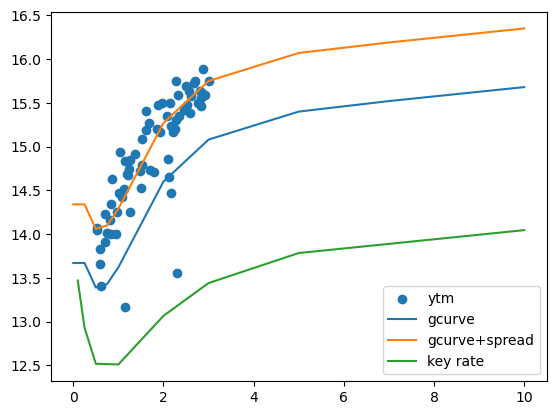

In [18]:
date_filter = pd.datetime(2026, 7,30)

rates = gcurve[gcurve['date']==date_filter].iloc[:, 1:11].to_numpy()[0]
tenors = [0,0.25, 0.5, 0.75, 1,2,3,5,7,10]
df_to_plot = bonds_corp2[(bonds_corp2['date']==date_filter)&
                         (bonds_corp2['liquidity'].isin(['high', 'mid'])&
                         (bonds_corp2['maturity']>0.5))]

spread = gspread[gspread['date']==date_filter]['spread avg']
plt.scatter(df_to_plot['maturity'], df_to_plot['ytm']*100, label='ytm')

plt.plot(tenors, rates, label = 'gcurve')
plt.plot(tenors, rates+spread.iloc[0]/100, label = 'gcurve+spread')
plt.plot([0.1, 0.25, 0.5, 1, 2, 3, 5, 10], df_to_plot.iloc[0, 26:34].to_numpy(), label='key rate')
plt.legend()